# Model 1 v3 – 06 Data Preparation (hard negatives: photos of people and hands)
**Why:** Stress test of the v2 app (19 Oct) – grayscale PHOTOS of a hand and of legs were accepted as X-rays (p ≈ 0.91).
Cause: the v2 NON_XRAY class contains no photos of people or body parts (only microscopy, OCT, skin close-ups, MRI, CT,
ultrasound, animals, objects, vegetables, vehicles), so "limb shape" was enough to look like an X-ray.
**Fix:** add photos of people (full body), zoomed crops of people (limb close-ups) and photos of hands as NON_XRAY.
Everything else stays exactly as in v2 (same images, same splits, same preprocessing).
**Inputs:** outputs/model1_v2/manifest_split_v2.csv + cache_224_v2.npz, Hugging Face datasets (downloaded here)
**Outputs:** NON_XRAY_extra/{People_HAR, People_crops_HAR, Hands_photos}, outputs/model1_v3/ (manifest_split_v3.csv, cache_224_v3.npz)
**Note:** the real-world stress-test photos are NOT used here – they stay in UNSEEN_TEST for notebook 08.

In [1]:
# ===== SETTINGS =====
from pathlib import Path
DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
V2_DIR     = DRIVE_ROOT / 'outputs' / 'model1_v2'
OUT_DIR    = DRIVE_ROOT / 'outputs' / 'model1_v3'
NEG_DIR    = DRIVE_ROOT / 'NON_XRAY_extra'          # new hard negatives are saved here (folder name = source)

SEED     = 42
N_PEOPLE = 600     # full photos of people (arms, legs, feet visible)
N_CROPS  = 400     # zoomed crops of OTHER people photos (close-ups of limbs / body parts)
N_HANDS  = 600     # photos of hands
HF_PEOPLE = 'Bingsu/Human_Action_Recognition'         # public HF dataset, 15 everyday actions (ODbL)
HF_HANDS  = 'pencaharlangit/hand-gesture-small-3000'   # public HF dataset, photos with hands

In [2]:
!pip install -q datasets
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd, io, hashlib
from PIL import Image, ImageOps
from tqdm.auto import tqdm
OUT_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
v2 = pd.read_csv(V2_DIR / 'manifest_split_v2.csv')
print('v2 manifest:', v2.shape, '| v2 cache exists:', (V2_DIR / 'cache_224_v2.npz').exists())

Mounted at /content/drive
v2 manifest: (8537, 11) | v2 cache exists: True


## Step 1 – Download the new hard negatives
Full photos and crops come from DIFFERENT photos (no photo is used twice). Skipped if the folders already exist.

In [3]:
from datasets import load_dataset

def save_images(items, folder, prefix):
    folder.mkdir(parents=True, exist_ok=True)
    for k, im in tqdm(items, desc=folder.name):
        im.convert('RGB').save(folder / f'{prefix}_{k:05d}.jpg', quality=95)
    print('Saved', len(list(folder.glob('*.jpg'))), 'images ->', folder)

def random_crop(im, rng):                          # close-up: 35–60 % of the width and height
    w, h = im.size; f = rng.uniform(0.35, 0.6); cw, ch = int(w * f), int(h * f)
    x, y = int(rng.integers(0, w - cw + 1)), int(rng.integers(0, h - ch + 1))
    return im.crop((x, y, x + cw, y + ch))

people_dir, crops_dir, hands_dir = NEG_DIR / 'People_HAR', NEG_DIR / 'People_crops_HAR', NEG_DIR / 'Hands_photos'

if len(list(people_dir.glob('*.jpg'))) >= N_PEOPLE and len(list(crops_dir.glob('*.jpg'))) >= N_CROPS:
    print('Already saved: People_HAR, People_crops_HAR')
else:
    ds = load_dataset(HF_PEOPLE, split='train')
    idx = rng.permutation(len(ds))[:N_PEOPLE + N_CROPS]
    save_images([(int(k), ds[int(k)]['image']) for k in idx[:N_PEOPLE]], people_dir, 'har')
    save_images([(int(k), random_crop(ds[int(k)]['image'], rng)) for k in idx[N_PEOPLE:]], crops_dir, 'harcrop')

if len(list(hands_dir.glob('*.jpg'))) >= N_HANDS:
    print('Already saved: Hands_photos')
else:
    ds = load_dataset(HF_HANDS, split='train')
    idx = rng.permutation(len(ds))[:N_HANDS]
    save_images([(int(k), ds[int(k)]['image']) for k in idx], hands_dir, 'hand')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/4.70k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  229MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/train-00000-of-00001-bfc804f06605d1(…): reconstructing file:   0%|          |  0.00B / 23.8MB            

data/train-00000-of-00001-bfc804f06605d1(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2991 [00:00<?, ? examples/s]

Hands_photos:   0%|          | 0/600 [00:00<?, ?it/s]

Saved 600 images -> /content/drive/MyDrive/Research/NON_XRAY_extra/Hands_photos


## Step 2 – Look at the new images (grayscale, as the model sees them)
Check: photos of people / body parts / hands, no X-rays.

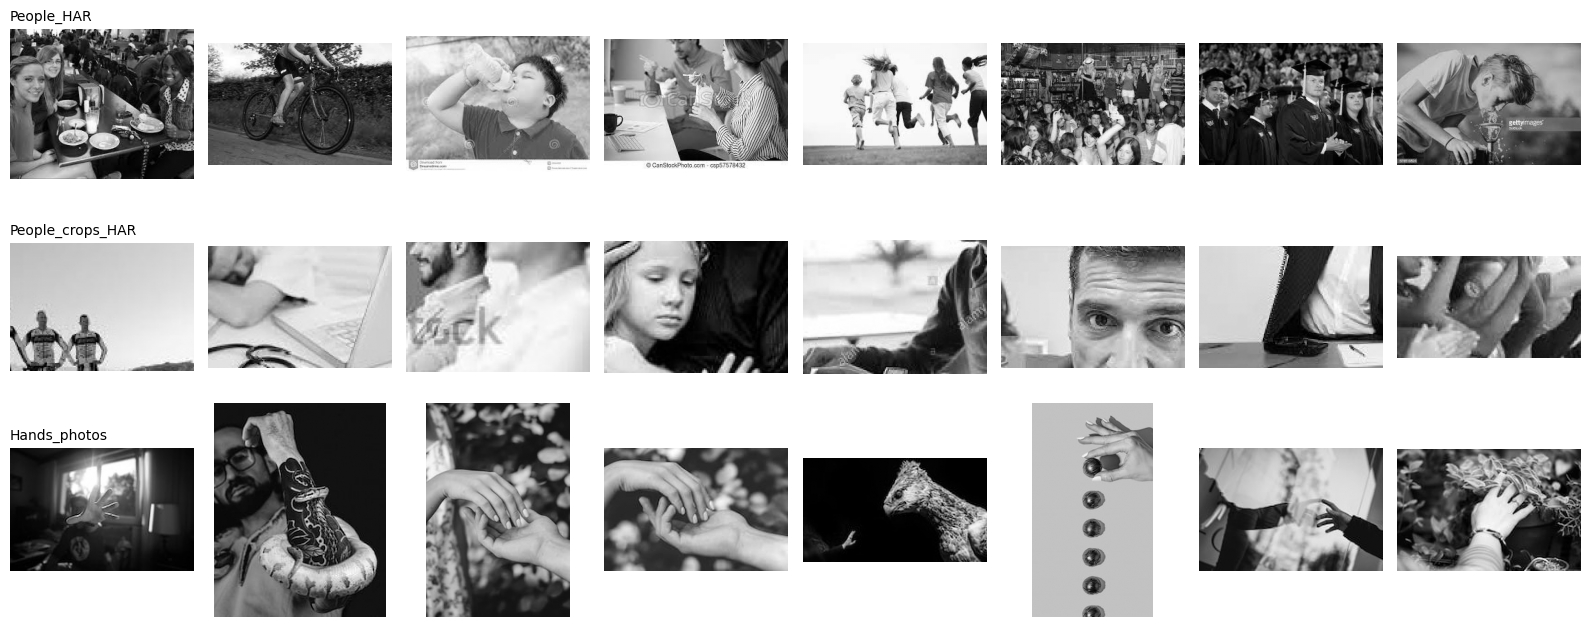

In [4]:
import matplotlib.pyplot as plt
show_rng = np.random.default_rng(0)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for row, d in zip(axes, [people_dir, crops_dir, hands_dir]):
    files = sorted(d.glob('*.jpg'))
    for ax, k in zip(row, show_rng.choice(len(files), 8, replace=False)):
        ax.imshow(Image.open(files[k]).convert('L'), cmap='gray'); ax.axis('off')
    row[0].set_title(d.name, fontsize=10, loc='left')
plt.tight_layout(); plt.show()

## Step 3 – Preprocess (same as v2), remove exact duplicates, split 70/15/15 per source

In [5]:
IMG_SIZE = 224

def prep_pil(im):                                   # identical to the v2 data preparation (notebook 03)
    im = ImageOps.exif_transpose(im)
    if im.mode in ('I;16', 'I;16B', 'I;16L', 'I', 'F'):
        a = np.asarray(im, dtype=np.float32); a = (a - a.min()) / max(a.max() - a.min(), 1) * 255
        im = Image.fromarray(a.astype(np.uint8))
    if im.mode == 'P': im = im.convert('RGBA')
    if im.mode in ('RGBA', 'LA'):
        bg = Image.new('RGBA', im.size, (0, 0, 0, 255)); im = Image.alpha_composite(bg, im.convert('RGBA'))
    im = im.convert('L'); w, h = im.size; s = max(w, h)
    canvas = Image.new('L', (s, s), 0); canvas.paste(im, ((s - w) // 2, (s - h) // 2))
    return np.asarray(canvas.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

new = pd.DataFrame([{'path': str(p), 'label': 'NON_XRAY', 'source': 'new_' + d.name, 'group': 'new_' + p.stem}
                    for d in [people_dir, crops_dir, hands_dir] for p in sorted(d.glob('*.jpg'))])
imgs, md5s = [], []
for p in tqdm(new.path):
    data = Path(p).read_bytes(); md5s.append(hashlib.md5(data).hexdigest())
    with Image.open(io.BytesIO(data)) as im: imgs.append(prep_pil(im))
new['md5'] = md5s; Xn = np.stack(imgs)

keep = ~(new.md5.duplicated() | new.md5.isin(v2.md5))
print('New images:', len(new), '| exact duplicates removed:', int((~keep).sum()))
new, Xn = new[keep].reset_index(drop=True), Xn[keep.values]

split_rng = np.random.default_rng(SEED)
new['split'] = ''
for src, g in new.groupby('source'):
    idx = split_rng.permutation(g.index.values); n = len(idx); a, b = int(0.70 * n), int(0.85 * n)
    new.loc[idx[:a], 'split'] = 'train'; new.loc[idx[a:b], 'split'] = 'val'; new.loc[idx[b:], 'split'] = 'test'
print(new.groupby(['source', 'split']).size().unstack().to_string())

  0%|          | 0/1600 [00:00<?, ?it/s]

New images: 1600 | exact duplicates removed: 0
split                 test  train  val
source                                
new_Hands_photos        90    420   90
new_People_HAR          90    420   90
new_People_crops_HAR    60    280   60


## Step 4 – Build the v3 dataset = v2 dataset (unchanged) + new hard negatives
The v2 cache is copied unchanged; new images are appended at the end (cache_idx continues after the v2 rows).

In [6]:
cache = np.load(V2_DIR / 'cache_224_v2.npz', allow_pickle=True)
X2, P2 = cache['images'], cache['paths']
new['keep'], new['y'] = True, 0
new['cache_idx'] = len(X2) + np.arange(len(new))
data = pd.concat([v2, new.reindex(columns=v2.columns)], ignore_index=True)

X3 = np.concatenate([X2, Xn]); P3 = np.concatenate([P2.astype(str), new.path.values.astype(str)])
assert (P3[data.cache_idx.values] == data.path.values).all(), 'Manifest and cache do not match!'
np.savez_compressed(OUT_DIR / 'cache_224_v3.npz', images=X3, paths=P3)
data.to_csv(OUT_DIR / 'manifest_split_v3.csv', index=False)

print(pd.crosstab(data.label, data.split, margins=True)[['train', 'val', 'test', 'All']])
print('\nGroups spread over more than one split:', (data.groupby('group').split.nunique() > 1).sum())
print('Saved:', OUT_DIR / 'manifest_split_v3.csv', '| cache', X3.shape)

split     train   val  test    All
label                             
NON_XRAY   3447   739   738   4924
X_RAY      3689   759   765   5213
All        7136  1498  1503  10137

Groups spread over more than one split: 0
Saved: /content/drive/MyDrive/Research/outputs/model1_v3/manifest_split_v3.csv | cache (10285, 224, 224)


## Summary – Model 1 v3 data
Added 1,600 NON_XRAY photos: People_HAR 600, People_crops_HAR 400 (limb close-ups from different photos), Hands_photos 600.
0 exact duplicates; split 70/15/15 per source; groups across splits: 0.
v3 dataset: 10,137 images (NON_XRAY 4,924 | X_RAY 5,213 — X-ray images and splits identical to v2).